# Práctica 3. Monedas y microplásticos

**Asignatura:** Visión por Computador · Grado en Ingeniería Informática · ULPGC
**Autores:** Naiara Díaz Hernández y Alejandro José Martel Torres

Este cuaderno resuelve las dos tareas propuestas en la práctica 3, cada celda va precedida de una breve explicación de qué se hace, la conclusión de resultados se plantean en el readme. En ninguna de las tareas se utilizan modelos de aprendizaje profundo, ni para segmentar ni para clasificar. A continuación, se encuentran las tareas planteadas:

- **Tarea 1.** Detectar monedas de euro, calibrar la escala (mm/píxel) con una moneda de valor conocido, clasificarlas por color y diámetro y calcular su valor total, tanto sobre una imagen estática como en un demostrador en vivo con cámara
- **Tarea 2.** Segmentar partículas de microplásticos, extraer características geométricas y visuales de las imágenes de entrenamiento y aprender un clasificador (FRA, PEL y TAR) que se evalúa sobre `MPs_test.jpg` con métricas y matriz de confusión

## Paquetes

Las librerías utilizadas para el desarrollo de la práctica son las siguientes:

- `cv2 (OpenCV)`: para realizar la lectura, conversión de color, detección de círculos y bordes, segmentación, extracción de contornos y captura de vídeo.
- `numpy`: para procesar las imágenes como arrays y realizar los cálculos de las características y del clasificador.
- `matplotlib`: nos permite mostrar las imágenes en **RGB** frente a OpenCV que trabaja en **BGR**, además de las matrices de confusión.
- `csv`: para leer las anotaciones del test.

In [ ]:
import csv
import cv2
import numpy as np
import matplotlib.pyplot as plt

## 1. Detección y valoración de monedas
### 1.1. Funciones de detección y clasificación

**Planteamiento.** El clic sobre una moneda de valor conocido fija la escala mm/píxel (`diámetro real / diámetro en píxeles`). Con esa escala, cada círculo se asigna a la moneda cuyo diámetro real es más cercano. El radio de Hough se afina antes con un ajuste a los bordes, porque su error de unos píxeles ya confunde monedas vecinas. Como algunas monedas tienen diámetros muy parecidos (1 € y 50 cts difieren en solo 1.1 mm), primero se clasifica el grupo de color de cada moneda (`cobre`, `oro`, `1euro` o `2euro`) y el diámetro solo decide entre las monedas de ese grupo. Las bimetálicas se detectan comparando el croma en Lab del núcleo con el de la corona. Si ninguna se parece (diferencia > `TOL_MM`) se marca como `?` (objeto que no es moneda).

In [2]:
# Diámetros reales (mm) de las monedas de euro
DIAMETROS_MM = {2.00: 25.75, 1.00: 23.25, 0.50: 24.35, 0.20: 22.25,
                0.10: 19.75, 0.05: 21.25, 0.02: 18.75, 0.01: 16.25}

TOL_MM = 1.8          # tolerancia (mm) respecto al diámetro de la moneda más cercana de su grupo
SOPORTE_MIN = 0.5     # fracción mínima de la circunferencia con borde (descarta falsos círculos)


def soporte_borde(bordes, x, y, r, n=90, tol=3):
    """Fracción de puntos de la circunferencia que tienen borde cerca."""
    h, w = bordes.shape
    ok = validos = 0
    for a in np.linspace(0, 2 * np.pi, n, endpoint=False):
        px = int(round(x + r * np.cos(a)))
        py = int(round(y + r * np.sin(a)))
        if 0 <= px < w and 0 <= py < h:
            validos += 1
            ok += bool(bordes[max(py - tol, 0):py + tol + 1, max(px - tol, 0):px + tol + 1].any())
    return ok / validos if validos else 0.0


def refinar_circulo(gris, x, y, r, n_ang=120, banda=0.2):
    """Hough da el radio con error de varios píxeles. Se afina buscando, en cada dirección,
    el borde más fuerte cerca de r y ajustando una circunferencia a esos puntos."""
    gris_suave = cv2.GaussianBlur(gris.astype(np.float32), (5, 5), 1.0)
    rs = np.linspace(r * (1 - banda), r * (1 + banda), max(int(r * banda * 10), 8))
    ang = np.linspace(0, 2 * np.pi, n_ang, endpoint=False)
    mx = (x + np.outer(np.cos(ang), rs)).astype(np.float32)
    my = (y + np.outer(np.sin(ang), rs)).astype(np.float32)
    perfil = cv2.remap(gris_suave, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    idx = np.abs(np.diff(perfil, axis=1)).argmax(axis=1)
    rr = (rs[idx] + rs[idx + 1]) / 2
    px, py = x + np.cos(ang) * rr, y + np.sin(ang) * rr
    for _ in range(3):                                    # ajuste por mínimos cuadrados con descarte de outliers
        if len(px) < n_ang // 2:
            return x, y, r
        A = np.c_[2 * px, 2 * py, np.ones_like(px)]
        cx, cy, c = np.linalg.lstsq(A, px ** 2 + py ** 2, rcond=None)[0]
        rad = np.sqrt(c + cx ** 2 + cy ** 2)
        resid = np.abs(np.hypot(px - cx, py - cy) - rad)
        buenos = resid <= max(1.2, 2.0 * np.median(resid))
        px, py = px[buenos], py[buenos]
    return float(cx), float(cy), float(rad)


def detectar_circulos(bgr, min_r, max_r):
    """Detecta monedas combinando medianBlur (como en el notebook base) y eliminando solapes."""
    gris = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    # medianBlur preserva el borde exterior de la moneda de 1€ pero borra el relieve interno
    gris_suave = cv2.medianBlur(gris, 7)
    
    circ = cv2.HoughCircles(
        gris_suave, cv2.HOUGH_GRADIENT, dp=1,
        minDist=int(min_r * 1.8),
        param1=90, param2=34,   # Un poco más sensible para no perder la moneda de 1 euro
        minRadius=min_r, maxRadius=max_r
    )
    if circ is None:
        return []
        
    bordes = cv2.Canny(gris_suave, 25, 90) # Umbral bajo en 30 para captar el borde plateado de 1€
    candidatos = [refinar_circulo(gris, x, y, r) for x, y, r in circ[0]
                  if soporte_borde(bordes, x, y, r) >= SOPORTE_MIN]
    
    # Ordenar de mayor a menor radio y descartar círculos contenidos dentro de otro
    candidatos.sort(key=lambda c: c[2], reverse=True)
    limpios = []
    for x, y, r in candidatos:
        if not any(np.hypot(x - cx, y - cy) < cr * 0.85 for cx, cy, cr in limpios):
            limpios.append((x, y, r))
    return limpios


def circulo_en(circulos, px, py):
    """Círculo (el de menor radio) que contiene el punto (px, py), o None."""
    dentro = [c for c in circulos if (px - c[0]) ** 2 + (py - c[1]) ** 2 <= c[2] ** 2]
    return min(dentro, key=lambda c: c[2]) if dentro else None


def calibrar(circulo, valor_ref):
    """mm por píxel a partir de una moneda de valor conocido."""
    return DIAMETROS_MM[valor_ref] / (2 * circulo[2])


GRUPOS_MONEDAS = {
    'cobre': {0.05: 21.25, 0.02: 18.75, 0.01: 16.25},
    'oro':   {0.50: 24.35, 0.20: 22.25, 0.10: 19.75},
    '1euro': {1.00: 23.25},
    '2euro': {2.00: 25.75}
}

def detectar_grupo_color(bgr, x, y, r):
    """Clasifica la moneda en 'cobre', 'oro', '1euro' o '2euro' analizando centro y corona."""
    h, w = bgr.shape[:2]
    # Recortar ROI alrededor de la moneda para ir rápido en vídeo
    x0, y0 = max(0, int(x - r)), max(0, int(y - r))
    x1, y1 = min(w, int(x + r + 1)), min(h, int(y + r + 1))
    roi = bgr[y0:y1, x0:x1]
    if roi.size == 0:
        return None

    lab = cv2.cvtColor(roi, cv2.COLOR_BGR2LAB).astype(np.float32)
    hsv = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV).astype(np.float32)

    yy, xx = np.mgrid[y0:y1, x0:x1]
    dist_norm = np.hypot(xx - x, yy - y) / max(r, 1.0)

    # Máscaras de disco interno (evita el borde) y corona exterior
    m_centro = dist_norm <= 0.50
    m_corona = (dist_norm >= 0.62) & (dist_norm <= 0.85)
    m_total  = dist_norm <= 0.82

    if not m_centro.any() or not m_corona.any():
        return None

    # Croma en Lab (distancia al gris neutro 128, 128) y Saturación en HSV
    A_c, B_c = lab[:, :, 1][m_centro] - 128, lab[:, :, 2][m_centro] - 128
    A_r, B_r = lab[:, :, 1][m_corona] - 128, lab[:, :, 2][m_corona] - 128
    
    croma_centro = np.median(np.hypot(A_c, B_c))
    croma_corona = np.median(np.hypot(A_r, B_r))
    diff_bimet   = croma_corona - croma_centro

    # 1. Detectar bimetálicas por diferencia de color entre corona y núcleo
    if diff_bimet > 6.5:       # Corona dorada (más color) y centro plateado -> 1 EUR
        return '1euro'
    elif diff_bimet < -6.5:    # Centro dorado y corona plateada -> 2 EUR
        return '2euro'

    # 2. Si es uniforme (oro o cobre), miramos la relación Rojo (A) vs Amarillo (B)
    A_tot = np.median(lab[:, :, 1][m_total] - 128)
    B_tot = np.median(lab[:, :, 2][m_total] - 128)
    
    # El cobre tiene bastante componente A (rojo); el oro domina claramente en B (amarillo)
    if A_tot > 0.38 * B_tot and A_tot > 4.0:
        return 'cobre'
    else:
        return 'oro'


def valor_de(bgr, x, y, radio_px, mm_por_px, tol=TOL_MM):
    """Combina el grupo de color con el diámetro medido para asignar el valor."""
    d = 2 * radio_px * mm_por_px
    grupo = detectar_grupo_color(bgr, x, y, radio_px)
    
    # Si el tamaño está muy lejos de cualquier moneda real, descartar
    if d < 14.5 or d > 27.5 or grupo is None:
        return None, d

    # Candidatos del grupo de color detectado
    candidatos = dict(GRUPOS_MONEDAS[grupo])

    # Margen de seguridad: si falla el contraste bimetálico por un reflejo fuerte,
    # permitimos que 1€ y 2€ entren como candidatos si el diámetro encaja muy bien
    if grupo in ('1euro', '2euro'):
        candidatos = {1.00: 23.25, 2.00: 25.75}

    valor, d_ref = min(candidatos.items(), key=lambda kv: abs(kv[1] - d))
    
    # Si la diferencia supera la tolerancia dentro del grupo, hacemos fallback general
    if abs(d_ref - d) > tol:
        valor_gen, d_gen = min(DIAMETROS_MM.items(), key=lambda kv: abs(kv[1] - d))
        return (valor_gen if abs(d_gen - d) <= 1.0 else None), d

    return valor, d


def clasificar_monedas(bgr, circulos, mm_por_px):
    return [(x, y, r) + valor_de(bgr, x, y, r, mm_por_px) for x, y, r in circulos]

def resumen(res):
    """Cuenta por valor y total en euros."""
    valores = [t[3] for t in res if t[3] is not None]
    cuenta = {v: valores.count(v) for v in sorted(set(valores), reverse=True)}
    total = round(sum(valores), 2)
    return len(valores), cuenta, total


def dibujar(bgr, res):
    out = bgr.copy()
    for x, y, r, v, d in res:
        color = (0, 255, 0) if v is not None else (0, 0, 255)
        cv2.circle(out, (int(x), int(y)), int(r), color, 2)
        cv2.putText(out, f"{v:.2f}" if v is not None else "?", (int(x - r / 2), int(y)),
                    cv2.FONT_HERSHEY_SIMPLEX, max(r / 60, 0.4), color, 2)
    return out

### 1.2. Resolución con imagen estática

Se detectan los círculos de `images/Monedas.jpg`, se muestran sobre la imagen y se espera el clic del usuario sobre la moneda de valor `VALOR_REF`.

**Pasos que sigue el planteamiento de la solución:**
1. Se detectan los círculos con `detectar_circulos` (Hough sobre la imagen suavizada con `medianBlur`, descarte de falsos círculos por falta de borde, refinado del radio y eliminación de círculos contenidos en otro).
2. Se calcula la escala mm/píxel con el círculo sobre el que se hace clic (`calibrar`).
3. Se clasifica cada moneda con `clasificar_monedas` (grupo de color y diámetro más cercano dentro del grupo).
4. Se muestra el recuento por valor, el total en euros y la imagen con cada moneda rodeada en verde con su valor (en rojo con `?` si no se reconoce).

Escala: 0.1260 mm/px
Monedas: 8   (círculos descartados: 0)
  2.00 EUR x 1
  1.00 EUR x 1
  0.50 EUR x 1
  0.20 EUR x 1
  0.10 EUR x 1
  0.05 EUR x 1
  0.02 EUR x 1
  0.01 EUR x 1
TOTAL: 3.88 EUR


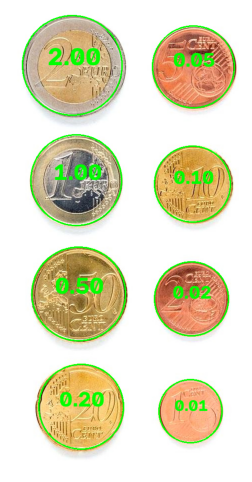

In [ ]:
# --- Imagen estática: clic sobre una moneda de valor conocido ---
VALOR_REF = 1.00                 # valor de la moneda sobre la que vas a hacer clic
ARCHIVO = 'images/Monedas.jpg'
ESCALA_VISTA = 0.5               # solo para que la ventana quepa en pantalla

img = cv2.imread(ARCHIVO)
alto, ancho = img.shape[:2]
circulos = detectar_circulos(img, int(0.06 * min(alto, ancho)), int(0.22 * min(alto, ancho)))

vista = cv2.resize(img, None, fx=ESCALA_VISTA, fy=ESCALA_VISTA)
for x, y, r in circulos:
    cv2.circle(vista, (int(x * ESCALA_VISTA), int(y * ESCALA_VISTA)), int(r * ESCALA_VISTA), (0, 255, 255), 2)

clic = {}
def on_click(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        clic['p'] = (x / ESCALA_VISTA, y / ESCALA_VISTA)     # coordenadas en la imagen original

VENTANA = f'Clic en la moneda de {VALOR_REF:.2f} EUR (ESC para salir)'
cv2.namedWindow(VENTANA)
cv2.setMouseCallback(VENTANA, on_click)
while 'p' not in clic:
    cv2.imshow(VENTANA, vista)
    if cv2.waitKey(20) == 27:
        break
cv2.destroyAllWindows()

c = circulo_en(circulos, *clic['p']) if 'p' in clic else None
if c is None:
    print('No se hizo clic dentro de una moneda detectada')
else:
    mm_por_px = calibrar(c, VALOR_REF)
    print(f'Escala: {mm_por_px:.4f} mm/px')
    res = clasificar_monedas(img, circulos, mm_por_px)  
    n, cuenta, total = resumen(res)
    print(f'Monedas: {n}   (círculos descartados: {len(res) - n})')
    for v, k in cuenta.items():
        print(f'  {v:.2f} EUR x {k}')
    print(f'TOTAL: {total:.2f} EUR')
    plt.figure(figsize=(8, 6)); plt.axis('off')
    plt.imshow(cv2.cvtColor(dibujar(img, res), cv2.COLOR_BGR2RGB))
    plt.savefig('tarea1_monedas.png', dpi=120, bbox_inches='tight')
    plt.show()

### 1.3. Demostrador en vivo

Se reutilizan las funciones anteriores sobre el vídeo de una cámara (un iPhone mediante DroidCam). Para que la clasificación sea estable entre fotogramas, en esta versión se añaden:

- **Seguimiento (*tracks*):** cada círculo se empareja con el del fotograma anterior por proximidad y se suavizan su posición y su radio.
- **Suavizado del color:** se aplica una media móvil exponencial (`ALPHA_COLOR`) a las características de color de cada moneda.
- **Histéresis:** el grupo `1euro` / `2euro` se decide con un umbral de entrada (`UMBRAL_ENTRADA`) y se mantiene hasta que baja del de salida (`UMBRAL_SALIDA`), para que las bimetálicas no oscilen entre grupos.
- **Máscaras de núcleo y corona** ajustadas a la frontera real entre ambos metales (aproximadamente 0.7·r): núcleo hasta 0.45·r y corona de 0.78·r a 0.92·r.
- **Banner semitransparente** con el recuento y el total, para que el texto no se superponga con las monedas.

Teclas: `1` = referencia 1 €, `2` = 2 €, `5` = 50 cts, `0` = 10 cts (elige antes del clic), clic = calibrar con esa moneda, `r` = borrar calibración, `ESC` = salir.
Si mueves la cámara cambia la escala: vuelve a calibrar.

In [4]:
GRUPOS_MONEDAS = {
    'cobre': {0.05: 21.25, 0.02: 18.75, 0.01: 16.25},
    'oro':   {0.50: 24.35, 0.20: 22.25, 0.10: 19.75},
    '1euro': {1.00: 23.25},
    '2euro': {2.00: 25.75}
}

# Parámetros de color (ajústalos mirando diff_bimet con monedas quietas)
UMBRAL_ENTRADA = 6.5   # para decidir 1euro / 2euro
UMBRAL_SALIDA  = 3.5   # histéresis: para dejar de serlo
ALPHA_COLOR    = 0.2   # suavizado temporal de las características de color


def medir_color(bgr, x, y, r):
    """Devuelve (diff_bimet, A_tot, B_tot) o None si no se puede medir."""
    h, w = bgr.shape[:2]
    x0, y0 = max(0, int(x - r)), max(0, int(y - r))
    x1, y1 = min(w, int(x + r + 1)), min(h, int(y + r + 1))
    roi = bgr[y0:y1, x0:x1]
    if roi.size == 0:
        return None

    lab = cv2.cvtColor(roi, cv2.COLOR_BGR2LAB).astype(np.float32)
    yy, xx = np.mgrid[y0:y1, x0:x1]
    dist_norm = np.hypot(xx - x, yy - y) / max(r, 1.0)

    m_centro = dist_norm <= 0.45
    m_corona = (dist_norm >= 0.78) & (dist_norm <= 0.92)
    m_total  = dist_norm <= 0.82

    if not m_centro.any() or not m_corona.any():
        return None

    A_c, B_c = lab[:, :, 1][m_centro] - 128, lab[:, :, 2][m_centro] - 128
    A_r, B_r = lab[:, :, 1][m_corona] - 128, lab[:, :, 2][m_corona] - 128

    croma_centro = np.median(np.hypot(A_c, B_c))
    croma_corona = np.median(np.hypot(A_r, B_r))
    diff_bimet = croma_corona - croma_centro

    A_tot = np.median(lab[:, :, 1][m_total] - 128)
    B_tot = np.median(lab[:, :, 2][m_total] - 128)
    return float(diff_bimet), float(A_tot), float(B_tot)


def grupo_con_histeresis(diff, A_tot, B_tot, anterior):
    if anterior == '1euro' and diff > UMBRAL_SALIDA:
        return '1euro'
    if anterior == '2euro' and diff < -UMBRAL_SALIDA:
        return '2euro'
    if diff > UMBRAL_ENTRADA:
        return '1euro'
    if diff < -UMBRAL_ENTRADA:
        return '2euro'
    return 'cobre' if (A_tot > 0.38 * B_tot and A_tot > 4.0) else 'oro'


tracks = []

def actualizar_tracks(frame, detectados, alpha=ALPHA_COLOR):
    """Empareja detecciones con tracks previos, suaviza posición/radio/color y decide el grupo."""
    nuevos, usados = [], set()
    for x, y, r in detectados:
        t = None
        for i, cand in enumerate(tracks):
            if i not in usados and np.hypot(x - cand['x'], y - cand['y']) < r * 0.4:
                t, _ = cand, usados.add(i)
                break

        f = medir_color(frame, x, y, r)
        if t is None:
            t = dict(x=x, y=y, r=r, feat=f, grupo=None)
        else:
            t['x'] = 0.6 * t['x'] + 0.4 * x
            t['y'] = 0.6 * t['y'] + 0.4 * y
            t['r'] = 0.75 * t['r'] + 0.25 * r
            if f is not None:
                t['feat'] = f if t['feat'] is None else tuple(
                    (1 - alpha) * a + alpha * b for a, b in zip(t['feat'], f))

        if t['feat'] is not None:
            t['grupo'] = grupo_con_histeresis(*t['feat'], t['grupo'])
        nuevos.append(t)
    tracks[:] = nuevos
    return nuevos


def clasificar_monedas_vivo(circulos, grupos, mm_por_px, tol=TOL_MM):
    res = []
    for (x, y, r), grupo in zip(circulos, grupos):
        d = 2 * r * mm_por_px
        if d < 14.5 or d > 27.5 or grupo is None:
            res.append((x, y, r, None, d))
            continue

        candidatos = {1.00: 23.25, 2.00: 25.75} if grupo in ('1euro', '2euro') else dict(GRUPOS_MONEDAS[grupo])
        valor, d_ref = min(candidatos.items(), key=lambda kv: abs(kv[1] - d))

        if abs(d_ref - d) > tol:
            valor_gen, d_gen = min(DIAMETROS_MM.items(), key=lambda kv: abs(kv[1] - d))
            valor = valor_gen if abs(d_gen - d) <= 1.0 else None

        res.append((x, y, r, valor, d))
    return res


def poner_banner(img, texto):
    f = cv2.FONT_HERSHEY_SIMPLEX
    (tw, th), base = cv2.getTextSize(texto, f, 0.8, 2)
    overlay = img.copy()
    cv2.rectangle(overlay, (0, 0), (img.shape[1], th + base + 20), (0, 0, 0), -1)
    cv2.addWeighted(overlay, 0.55, img, 0.45, 0, img)
    cv2.putText(img, texto, (10, th + 10), f, 0.8, (255, 255, 255), 2, cv2.LINE_AA)


# --- Bucle del demostrador en vivo ---
REFS = {ord('1'): 1.00, ord('2'): 2.00, ord('5'): 0.50, ord('0'): 0.10}
estado = {'mm_px': None, 'circulos': [], 'ref': 1.00}

def on_click_video(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        c = circulo_en(estado['circulos'], x, y)
        if c is not None:
            estado['mm_px'] = calibrar(c, estado['ref'])

cap = cv2.VideoCapture(1)
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
cv2.namedWindow('Demo monedas')
cv2.setMouseCallback('Demo monedas', on_click_video)

tracks.clear()

while True:
    ok, frame = cap.read()
    if not ok:
        break
    h, w = frame.shape[:2]
    actuales = detectar_circulos(frame, int(0.03 * min(h, w)), int(0.2 * min(h, w)))

    ts = actualizar_tracks(frame, actuales)
    estado['circulos'] = [(t['x'], t['y'], t['r']) for t in ts]
    grupos = [t['grupo'] for t in ts]

    if estado['mm_px'] is None:
        salida = frame.copy()
        for x, y, r in estado['circulos']:
            cv2.circle(salida, (int(x), int(y)), int(r), (0, 255, 255), 2)
        texto = f"Referencia {estado['ref']:.2f} EUR: haz clic en esa moneda"
    else:
        res = clasificar_monedas_vivo(estado['circulos'], grupos, estado['mm_px'])
        n, cuenta, total = resumen(res)
        salida = dibujar(frame, res)
        texto = f'Monedas: {n}   Total: {total:.2f} EUR'

    poner_banner(salida, texto)
    cv2.imshow('Demo monedas', salida)

    tecla = cv2.waitKey(1) & 0xFF
    if tecla == 27:
        break
    elif tecla in REFS:
        estado['ref'] = REFS[tecla]
    elif tecla == ord('r'):
        estado['mm_px'] = None

cap.release()
cv2.destroyAllWindows()

**Problemas observados:**
- Iluminación, reflejos y sombras: la clasificación depende del croma, por lo que los reflejos fuertes y el autoajuste de exposición y de balance de blancos de la cámara alteran el color percibido, sobre todo en las bimetálicas, que eran las que más oscilaban antes de introducir el seguimiento temporal y la histéresis.
- Cámara inclinada o a distinta distancia: la escala solo es válida para el plano y la distancia en la que se calibró; si se mueve la cámara hay que pulsar `r` y volver a calibrar.
- Monedas de diámetro parecido (20 cts / 1 € / 50 cts): si falla la detección bimetálica, el 1 € pasa al grupo `oro` y se confunde con la de 50 cts (1.1 mm de diferencia). La comprobación por color, el refinado del radio y la histéresis reducen el problema.
- Objetos que no son monedas y solapes: se descartan por falta de soporte de borde, por quedar fuera del rango de diámetros (14.5-27.5 mm) o por quedar contenidos en otro círculo; las monedas solapadas pueden perderse.

## 2. Clasificación de microplásticos
### 2.1. Segmentación, características y entrenamiento

**Enunciado.** Extraer características (geométricas y/o visuales) de las tres imágenes completas de partida y aprender patrones que permitan identificar las partículas en nuevas imágenes. Como imagen de test se proporciona `MPs_test.jpg` y sus anotaciones `MPs_test_bbs.csv`, con las que se deben obtener las métricas de la propuesta de clasificación, además de la matriz de confusión. No se admite el uso de modelos de aprendizaje profundo ni para segmentar ni para clasificar.

**Pasos que sigue el planteamiento de la solución:**
1. **Segmentación (visión clásica).** Se calcula la diferencia de color en Lab respecto a un fondo local (mediana de gran tamaño), que corrige las bandas y el viñeteo del escáner. El borde oscuro del escáner se atenúa en lugar de recortarse, se umbraliza con histéresis (el umbral se adapta al ruido de cada imagen), se limpia con morfología y se extraen los contornos con `cv2.findContours`.
2. **Características.** Se calculan 13 características por contorno, geométricas (`area`, `compacidad`, `extent`, `aspecto`, `elipse`, `dist`, `solidez`, `circ`), de luminosidad (`L_rel`, `L_std`, `oscuro`) y de color (`croma`, `sat`). Las de luminosidad son relativas al fondo local para que no dependan de la iluminación.
3. **Entrenamiento.** Se extraen las características de las partículas de las tres imágenes de entrenamiento, una por clase, y se estandarizan de forma robusta (mediana y MAD), que es inmune a los *outliers* de la segmentación.
4. **Clasificador.** Un kNN implementado con NumPy (k = 7), ponderado por 1/distancia y equilibrado por clase: el voto se divide por el número de ejemplos de la clase para que una clase abundante en el entrenamiento no gane por tamaño.

**Recortes y escala del entrenamiento.** Las imágenes de entrenamiento se utilizan con un recorte (`ENTRENAMIENTO`) para quedarse con la región donde están las partículas y dejar fuera el borde del escáner, y se reducen con un factor `F = 0.4` para agilizar el procesado. Todas las partículas que la segmentación encuentra dentro de la región recortada se utilizan para el entrenamiento y la imagen de test no se emplea en ningún momento para aprender.

In [5]:
CLASES = ['FRA', 'PEL', 'TAR']
AREA_MIN = 20
F = 0.4                  # factor de reducción de las fotos de entrenamiento
 
# Recorte de cada imagen de entrenamiento (región con partículas, sin el borde del escáner)
ENTRENAMIENTO = {
    'FRA': ('images/fragment-03-olympus-10-01-2020.JPG', (slice(0, 2500), slice(900, 4000))),
    'PEL': ('images/pellet-03-olympus-10-01-2020.JPG',   (slice(0, 2300), slice(900, 4000))),
    'TAR': ('images/tar-03-olympus-10-01-2020.JPG',      (slice(0, 2550), slice(900, 3700))),
}
# Todas independientes de escala e iluminación (L_rel y oscuro son relativas al fondo local)
COLUMNAS = ['area','compacidad', 'extent', 'aspecto', 'elipse', 'dist', 'solidez', 'circ',
            'L_rel', 'L_std', 'croma', 'sat', 'oscuro']
 
 
def _fondo(lab, frac=0.08, ds=4):
    """Fondo local = mediana de gran tamaño (sobre imagen reducida y con borde reflejado)."""
    h, w = lab.shape[:2]
    k = int(max(h, w) * frac / ds) | 1
    pad = k * ds // 2 + 4
    p = cv2.copyMakeBorder(lab, pad, pad, pad, pad, cv2.BORDER_REFLECT)
    s = cv2.resize(p, None, fx=1 / ds, fy=1 / ds, interpolation=cv2.INTER_AREA)
    s = np.stack([cv2.medianBlur(np.ascontiguousarray(s[:, :, i]), k) for i in range(3)], -1)
    s = cv2.resize(s, (p.shape[1], p.shape[0]), interpolation=cv2.INTER_CUBIC)
    return s[pad:pad + h, pad:pad + w].astype(np.float32)
 
 
def segmentar(bgr, recorte=None, escala=1.0):
    """Devuelve ((bgr, fondo_lab), binaria, contornos). El 1er elemento se pasa tal cual a caracteristicas()."""
    if recorte is not None:
        bgr = bgr[recorte]
    if escala != 1.0:
        bgr = cv2.resize(bgr, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)
    bgr = np.ascontiguousarray(bgr)
    h, w = bgr.shape[:2]
 
    # 1) diferencia de color (Lab) respecto al fondo local: corrige bandas y viñeteo del escáner
    lab = cv2.cvtColor(cv2.GaussianBlur(bgr, (3, 3), 0), cv2.COLOR_BGR2LAB)
    bg = _fondo(lab)
    d = np.sqrt(((lab.astype(np.float32) - bg) ** 2).sum(-1))
 
    # 2) el borde oscuro del escáner (~25 px) se atenúa en vez de recortarse (así no se pierden
    #    partículas pegadas al borde)
    yy, xx = np.mgrid[0:h, 0:w]
    dist = np.minimum.reduce([yy, h - 1 - yy, xx, w - 1 - xx]).astype(np.float32)
    d = d / (1 + 3 * np.exp(-dist / 20))
 
    # 3) umbral con histéresis; el umbral se adapta al ruido de fondo de cada imagen
    hi = max(15.0, 7 * float(np.median(d)))
    lo = hi * 2 / 3
    _, lb = cv2.connectedComponents((d > lo).astype(np.uint8), connectivity=8)
    keep = np.unique(lb[d > hi]); keep = keep[keep > 0]
    binaria = np.isin(lb, keep).astype(np.uint8) * 255
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))
 
    cont, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    area_max, lado_max = 0.05 * h * w, 0.20 * max(h, w)
    salida = [c for c in cont
              if AREA_MIN <= cv2.contourArea(c) <= area_max and max(cv2.boundingRect(c)[2:]) <= lado_max]
    return (bgr, bg), binaria, salida
 
 
def caracteristicas(c, img):
    bgr, bg = img
    area = cv2.contourArea(c)
    per = cv2.arcLength(c, True)
    x, y, w, h = cv2.boundingRect(c)
    (_, _), (rw, rh), _ = cv2.minAreaRect(c)
    if len(c) >= 5:
        _, (ea, eb), _ = cv2.fitEllipse(c)
        elipse = max(ea, eb) / max(min(ea, eb), 1e-6)
    else:
        elipse = 1.0
    M = cv2.moments(c)
    cx, cy = M['m10'] / M['m00'], M['m01'] / M['m00']
    d = np.hypot(c[:, 0, 0] - cx, c[:, 0, 1] - cy)
    (_, _), rc = cv2.minEnclosingCircle(c)
    hull = cv2.convexHull(c)
 
    mask = np.zeros((h, w), np.uint8)
    cv2.drawContours(mask, [c], -1, 255, -1, offset=(-x, -y))
    interior = cv2.erode(mask, np.ones((3, 3), np.uint8), iterations=2)
    if interior.sum() == 0:
        interior = mask
    m = interior > 0
    sub = bgr[y:y + h, x:x + w]
    lab = cv2.cvtColor(sub, cv2.COLOR_BGR2LAB).astype(np.float32)
    hsv = cv2.cvtColor(sub, cv2.COLOR_BGR2HSV).astype(np.float32)
    L, A, B = lab[:, :, 0][m], lab[:, :, 1][m] - 128, lab[:, :, 2][m] - 128
    L_fondo = bg[y:y + h, x:x + w, 0][m]
 
    f = {'area': area,
        'compacidad': per ** 2 / area,
         'extent': area / (w * h),
         'aspecto': max(rw, rh) / max(min(rw, rh), 1e-6),
         'elipse': elipse,
         'dist': d.min() / d.max(),
         'solidez': area / max(cv2.contourArea(hull), 1e-6),
         'circ': area / (np.pi * rc ** 2 + 1e-6),            # área / círculo mínimo: ~1 en pellets
         'L_rel': float((L - L_fondo).mean()),                # luminosidad respecto al fondo (TAR muy negativa)
         'L_std': float(L.std()),                              # textura (TAR rugoso)
         'croma': float(np.hypot(A, B).mean()),
         'sat': float(hsv[:, :, 1][m].mean()),
         'oscuro': float((L < L_fondo - 60).mean())}          # fracción de píxeles muy oscuros
    return f, (cx, cy)
 
 
X, y = [], []
for clase, (archivo, recorte) in ENTRENAMIENTO.items():
    im = cv2.imread(archivo)
    assert im is not None, f'No se encuentra {archivo}'
    img, _, cont = segmentar(im, recorte, escala=F)
    for c in cont:
        f, _ = caracteristicas(c, img)
        X.append([f[k] for k in COLUMNAS]); y.append(clase)
    print(f'{clase}: {len(cont)} partículas de entrenamiento')
X, y = np.array(X), np.array(y)
 
# Estandarización robusta (mediana / MAD): inmune a outliers de segmentación
mu = np.median(X, axis=0)
sigma = 1.4826 * np.median(np.abs(X - mu), axis=0) + 1e-6
n_clase = {c: int((y == c).sum()) for c in CLASES}
 
print('Media de cada característica por clase:')
print(f"{'':10}" + ''.join(f'{c:>11}' for c in COLUMNAS))
for c in CLASES:
    print(f'{c:10}' + ''.join(f'{v:11.2f}' for v in X[y == c].mean(axis=0)))
 
 
def predecir(feats, k=7, excluir_mismo=False):
    """kNN ponderado por 1/distancia y equilibrado por clase (el voto se divide por nº de
    ejemplos de la clase, para que una clase abundante en entrenamiento no gane por tamaño)."""
    Z = np.clip((np.array(feats) - mu) / sigma, -6, 6)
    T = np.clip((X - mu) / sigma, -6, 6)
    out = []
    for z in Z:
        dist = np.linalg.norm(T - z, axis=1)
        if excluir_mismo:
            dist[dist < 1e-9] = np.inf
        idx = np.argsort(dist)[:k]
        votos = dict.fromkeys(CLASES, 0.0)
        for i in idx:
            votos[y[i]] += 1.0 / (dist[i] + 1e-3) / n_clase[y[i]]
        out.append(max(votos, key=votos.get))
    return np.array(out)
 
print('\nAcierto en entrenamiento (leave-one-out):',
      round(float(np.mean(predecir(X, excluir_mismo=True) == y)), 3))

FRA: 69 partículas de entrenamiento
PEL: 54 partículas de entrenamiento
TAR: 54 partículas de entrenamiento
Media de cada característica por clase:
                 area compacidad     extent    aspecto     elipse       dist    solidez       circ      L_rel      L_std      croma        sat     oscuro
FRA            562.41      22.95       0.60       1.53       1.64       0.46       0.89       0.54     -36.64      11.13      10.89      55.37       0.18
PEL            879.26      14.85       0.73       1.13       1.19       0.76       0.97       0.79     -51.14      12.76      12.11      81.71       0.26
TAR            625.50      15.52       0.68       1.30       1.38       0.63       0.96       0.69     -91.30      35.00       1.62      21.38       0.78

Acierto en entrenamiento (leave-one-out): 0.864


### 2.2. Evaluación sobre la imagen de test

Se segmenta `images/MPs_test.jpg`, se clasifica cada contorno y se empareja con las anotaciones de `MPs_test_bbs.csv`: cada anotación se asocia al contorno de mayor área cuyo centroide cae dentro de su caja. Si ningún contorno cumple la condición, la partícula anotada se cuenta como `NO_DET` (no detectada por la segmentación). Con ello se calculan la matriz de confusión (filas: clase anotada, columnas: clase predicha), la precisión, el *recall* y la F1 de cada clase y la *accuracy* global.

Anotaciones: 120 | contornos: 117 | sin detectar: 6 | contornos sin anotación: 4
Accuracy: 0.742

       precision    recall        F1     n
FRA         0.75      0.91      0.82    66
PEL         0.79      0.50      0.61    38
TAR         1.00      0.62      0.77    16


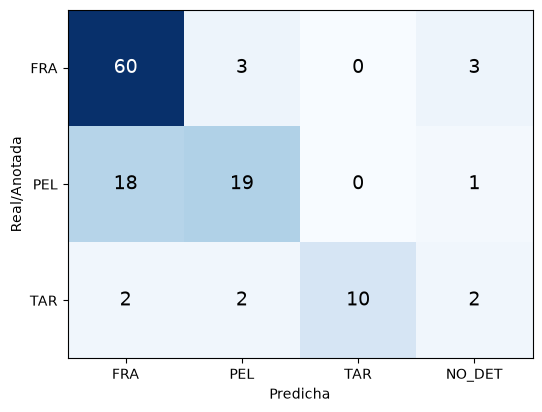

caja anotada: mediana 676.0  min 180  max 3078
áreas contornos test: [40, 41, 46, 68, 75, 85, 95, 145, 164, 169, 170, 176, 178, 184, 193, 194, 197, 198, 204, 220, 234, 239, 240, 240, 242, 242, 249, 252, 252, 252, 256, 256, 269, 274, 275, 278, 280, 286, 287, 289, 291, 292, 298, 299, 301, 301, 306, 307, 312, 313, 318, 337, 345, 345, 349, 353, 354, 362, 368, 372, 373, 383, 385, 385, 386, 387, 390, 398, 399, 403, 406, 412, 412, 418, 419, 422, 431, 435, 438, 440, 447, 457, 461, 466, 476, 487, 498, 509, 519, 527, 528, 541, 548, 557, 561, 567, 571, 574, 585, 636, 772, 804, 817, 869, 926, 936, 984, 984, 1040, 1052, 1181, 1183, 1205, 1221, 1390, 1448, 1886]
tamaño test (1186, 790, 3) | tamaño train [(3456, 4608, 3), (3456, 4608, 3), (3456, 4608, 3)]


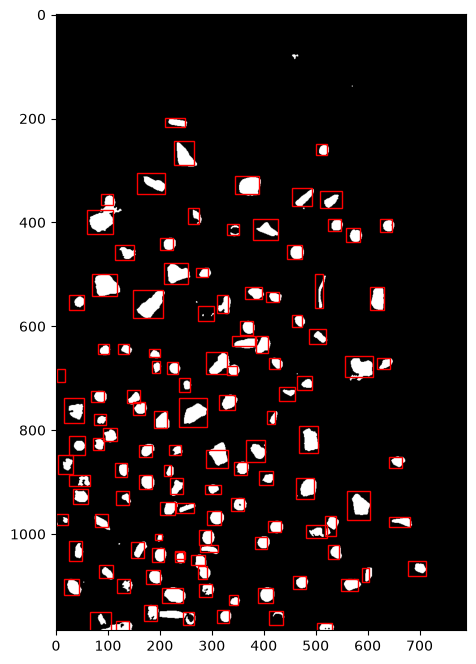

In [ ]:
# --- EVALUACIÓN sobre la imagen de test (solo se usa para evaluar) ---
def cargar_anotaciones(archivo_csv):
    with open(archivo_csv, newline='') as fh:
        return [(r['label'], int(r['x_min']), int(r['y_min']), int(r['x_max']), int(r['y_max']))
                for r in csv.DictReader(fh)]

anot = cargar_anotaciones('MPs_test_bbs.csv')
test = cv2.imread('images/MPs_test.jpg')
gris_t, bin_t, cont_t = segmentar(test)

feats, centros, areas = [], [], []
for c in cont_t:
    f, ctr = caracteristicas(c, gris_t)
    feats.append([f[k] for k in COLUMNAS]); centros.append(ctr); areas.append(f['area'])
preds = predecir(feats) if feats else []

# Empareja cada anotación con el contorno cuyo centroide cae dentro de su caja (el de mayor área)
y_true, y_pred, usados = [], [], set()
for lab, x0, y0, x1, y1 in anot:
    cand = [i for i, (cx, cy) in enumerate(centros) if x0 <= cx <= x1 and y0 <= cy <= y1]
    y_true.append(lab)
    if cand:
        i = max(cand, key=lambda i: areas[i]); usados.add(i); y_pred.append(preds[i])
    else:
        y_pred.append('NO_DET')          # partícula anotada que la segmentación no encontró

print(f'Anotaciones: {len(anot)} | contornos: {len(cont_t)} | '
      f'sin detectar: {y_pred.count("NO_DET")} | contornos sin anotación: {len(cont_t) - len(usados)}')
ETIQ = CLASES + ['NO_DET']
cm = np.zeros((len(CLASES), len(ETIQ)), dtype=int)          # filas: real, columnas: predicha
for t, p in zip(y_true, y_pred):
    cm[CLASES.index(t), ETIQ.index(p)] += 1

print(f'Accuracy: {np.trace(cm) / cm.sum():.3f}\n')
print(f"{'':6}{'precision':>10}{'recall':>10}{'F1':>10}{'n':>6}")
for i, c in enumerate(CLASES):
    tp = cm[i, i]
    prec = tp / cm[:, i].sum() if cm[:, i].sum() else 0.0     # TP / (TP + FP)
    rec = tp / cm[i].sum() if cm[i].sum() else 0.0            # TP / (TP + FN)
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    print(f'{c:6}{prec:10.2f}{rec:10.2f}{f1:10.2f}{cm[i].sum():6d}')

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14)
plt.xticks(range(len(ETIQ)), ETIQ); plt.yticks(range(len(CLASES)), CLASES)
plt.xlabel('Predicha'); plt.ylabel('Real/Anotada')
plt.savefig('tarea2_matriz_confusion.png', dpi=120, bbox_inches='tight')
plt.show()

areas_gt = [(x1-x0)*(y1-y0) for _, x0, y0, x1, y1 in anot]
print('caja anotada: mediana', np.median(areas_gt), ' min', min(areas_gt), ' max', max(areas_gt))
print('áreas contornos test:', sorted(int(cv2.contourArea(c)) for c in cont_t))
print('tamaño test', test.shape, '| tamaño train', [cv2.imread(a).shape for a, _ in ENTRENAMIENTO.values()])
plt.figure(figsize=(10, 8)); plt.imshow(bin_t, cmap='gray')
for lab, x0, y0, x1, y1 in anot:
    plt.gca().add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0, fill=False, ec='r'))
plt.show()

Por último, se dibuja el contorno de cada partícula de la imagen de test coloreado según la clase predicha.

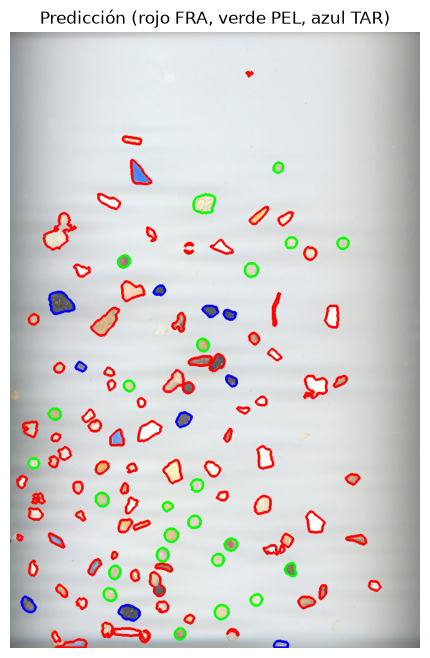

In [ ]:
# Resultado visual: contorno de cada partícula coloreado por la clase predicha
COLORES = {'FRA': (0, 0, 255), 'PEL': (0, 255, 0), 'TAR': (255, 0, 0)}
vis = test.copy()
for c, p in zip(cont_t, preds):
    cv2.drawContours(vis, [c], -1, COLORES[p], 3)
plt.figure(figsize=(10, 8)); plt.axis('off')
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.title('Predicción (rojo FRA, verde PEL, azul TAR)')
plt.savefig('tarea2_prediccion.png', dpi=120, bbox_inches='tight')
plt.show()

**Problemas observados:**
- Partículas pegadas que la segmentación une en un solo contorno: hay menos contornos (117) que anotaciones (120) y algunos contornos tienen un área muy superior a la mediana de las cajas anotadas, por lo que probablemente son varias partículas unidas, lo que distorsiona sus características geométricas.
- Clase que más se confunde y por qué: los pellets (recall 0.50) son la clase peor reconocida; los fragmentos tienen un recall alto (0.91) pero una precisión de 0.75, de modo que absorben partículas de otras clases. El alquitrán tiene precisión 1.00 (cuando se predice TAR no falla), pero se pierde parte de las partículas (recall 0.62), en parte por las que la segmentación no detecta.
- Diferencias de iluminación entre entrenamiento y test: las imágenes de entrenamiento (3456×4608, reducidas con factor 0.4) y la de test (1186×790) difieren en resolución e iluminación, y solo se dispone de una imagen de entrenamiento por clase, lo que explica la bajada de acierto desde el 0.864 del entrenamiento (*leave-one-out*) hasta el 0.742 del test.